## Sistemas de control: Lab 2

### Parte 1: Preparación de la Experiencia

2 states have been removed from the model
[ 7.77156117e-16+2.02507945j  7.77156117e-16-2.02507945j
 -6.55500000e-01+0.77802298j -6.55500000e-01-0.77802298j]
[-0.+2.02507945j  0.-2.02507945j]


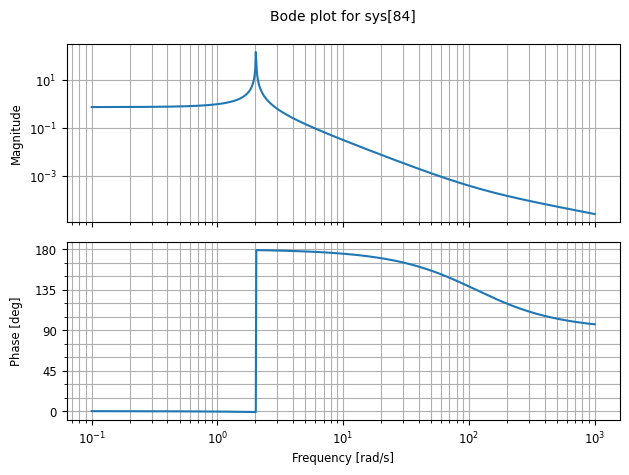

In [19]:
import control as ctrl
from numpy import linspace
import matplotlib.pyplot as plt

G = ctrl.tf([-0.02705, 0.06326], [1, 1.311, 1.035], inputs=['b'], outputs=['v'])

K = 1.311/.02705

G_lc = ctrl.tf([-0.02705, 0.06326*K],[1, 1.311-0.02705*K, 1.035+0.06326*K])

G_lc_producto = K*G/(1+K*G)
ctrl.minreal(G_lc_producto)
print(G_lc_producto.poles())

print(G_lc.poles())
G_lc.bode_plot()

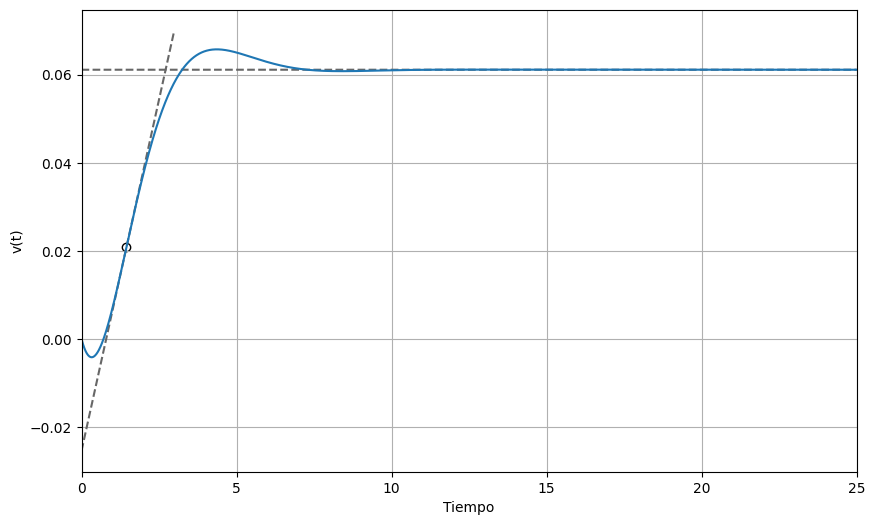

In [98]:
from numpy import polyfit, poly1d

plt.rcParams['figure.figsize'] = [10,6]

t = linspace(0,100,10000)

x, y = G.step_response(T=t)

dydx = [(y[i]-y[i-1])/(x[i]-x[i-1]) for i in range(1,len(x))]
d2ydx2 = [(dydx[i]-dydx[i-1])/(x[i]-x[i-1]) for i in range(1,len(x)-1)]

plt.xlim([0,25])

poly = polyfit(x[145:147], y[145:147], 1)

reg = []
for i in x:
    reg.append(0.03188135*i-0.0253592)

plt.plot(x[:300], reg[:300], linestyle='--', color='#676767')
plt.plot(x, [y[-1] for i in x], linestyle='--', color='#676767')
plt.grid()
plt.xlabel('Tiempo')
plt.ylabel('v(t)')

plt.plot(x, y)
plt.scatter(x[145], y[145], facecolor='white', edgecolor='black')

In [ ]:
print(poly)
print(y[145] - (0.03188135 * x[145] - 0.0253592))

[ 0.03188135 -0.0253592 ]
1.7487484169076417e-09
0.06112077294686093


### Parte 2: Experiencia de laboratorio